In [176]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
import pyarrow
from pathlib import Path

In [177]:
BASE_DIR = Path.cwd().resolve().parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

In [178]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_provinvial = BASE_DIR / "data"/"processed"/"LIM_PROVINCIAL_PERU.json"
peru = gpd.read_file(ruta_mapa)
provincias_peru = gpd.read_file(ruta_provinvial)

In [179]:
df_cap600 = pd.read_parquet(RAW_DIR / "14_CAP600.parquet")
df_caratula = pd.read_parquet(RAW_DIR / "CARATULA.parquet")

In [180]:
df_ancash = df_cap600.loc[df_cap600["NOMBREDD"] == "ANCASH"]
df_lalibertad = df_cap600.loc[df_cap600["NOMBREDD"] == "LA LIBERTAD"]

In [181]:
caratula_ancash = df_caratula.loc[df_caratula["NOMBREDD"] == "ANCASH"]
caratula_lalibertad = df_caratula.loc[df_caratula["NOMBREDD"] == "LA LIBERTAD"]

In [182]:
map_ancash = peru.loc[peru["NOMBDEP"] == "ANCASH"]
map_prov_ancash = provincias_peru.loc[provincias_peru["NOMBDEP"]== "ANCASH"]
map_lalibertad = peru.loc[peru["NOMBDEP"] == "LA LIBERTAD"]
map_prov_lalibertad = provincias_peru.loc[provincias_peru["NOMBDEP"]== "LA LIBERTAD"]

In [183]:
puntos_ancash = gpd.GeoDataFrame(
    caratula_ancash,
    geometry = gpd.points_from_xy(
        caratula_ancash["LONGITUD"],
        caratula_ancash["LATITUD"]
    ),
    crs = "EPSG:4326"
).copy()

In [184]:
puntos_lalibertad = gpd.GeoDataFrame(
    caratula_lalibertad,
    geometry = gpd.points_from_xy(
        caratula_lalibertad["LONGITUD"],
        caratula_lalibertad["LATITUD"]
    ),
    crs = "EPSG:4326"
).copy()

## La Libertad

### Manejo de residuos de cultivos

In [185]:
manejo_res_cult = {
    "P601_1": "Incineración",
    "P601_2": "Alimento animales",
    "P601_3": "Desecho",
    "P601_4": "Abono",
    "P601_5": "Deja en el campo",
    "P601_6": "Otro"
}

columnas_manejo_res_cult = list(manejo_res_cult.keys())

In [186]:
frec_manejo_res_cult = (
    df_lalibertad[columnas_manejo_res_cult]
    .sum()
    .sort_values(ascending=False)
    .rename(index=manejo_res_cult)
)

frec_manejo_res_cult = (frec_manejo_res_cult/len(df_lalibertad)*100).round(2)
frec_manejo_res_cult

Deja en el campo     68.48
Alimento animales    38.73
Abono                38.37
Incineración         21.98
Desecho               3.39
Otro                  0.14
dtype: float64

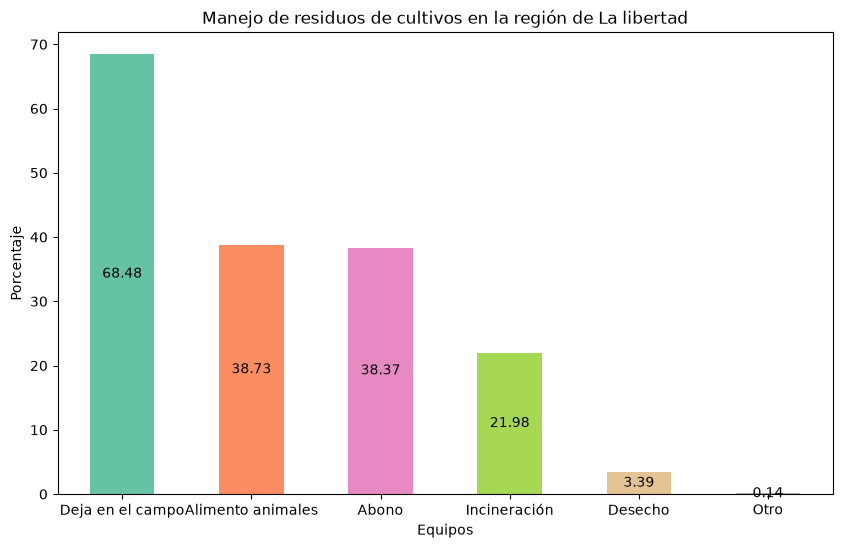

In [187]:
cmap = plt.get_cmap("Set2", len(frec_manejo_res_cult))
colores = [cmap(i) for i in range(len(frec_manejo_res_cult))]

gr_reg_manejo_res_cult = frec_manejo_res_cult.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_manejo_res_cult.set_title("Manejo de residuos de cultivos en la región de La libertad")
gr_reg_manejo_res_cult.set_xlabel("Equipos")
gr_reg_manejo_res_cult.set_ylabel("Porcentaje")  


for container in gr_reg_manejo_res_cult.containers:
    gr_reg_manejo_res_cult.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 0)
plt.show()

### Manejo de residuos de animales

In [188]:
manejo_res_anim = {
    "P602_1": "Incinera",
    "P602_2": "Entierra",
    "P602_3": "Desecha",
    "P602_4": "Abono",
    "P602_5": "Combustible",
    "P602_6": "Deja en el campo",
    "P602_7": "Otro",
    "P602_8": "No aplica"
}

columnas_manejo_res_anim = list(manejo_res_anim.keys())

In [189]:
frec_manejo_res_anim = (
    df_lalibertad[columnas_manejo_res_anim]
    .sum()
    .sort_values(ascending=False)
    .rename(index = manejo_res_anim)
)

frer_manejo_res_anim = (frec_manejo_res_anim/len(df_lalibertad)*100).round(2)
frer_manejo_res_anim

Abono               51.10
Deja en el campo    42.69
Desecha              5.23
Incinera             2.19
Combustible          1.13
Entierra             0.49
Otro                 0.00
No aplica            0.00
dtype: float64

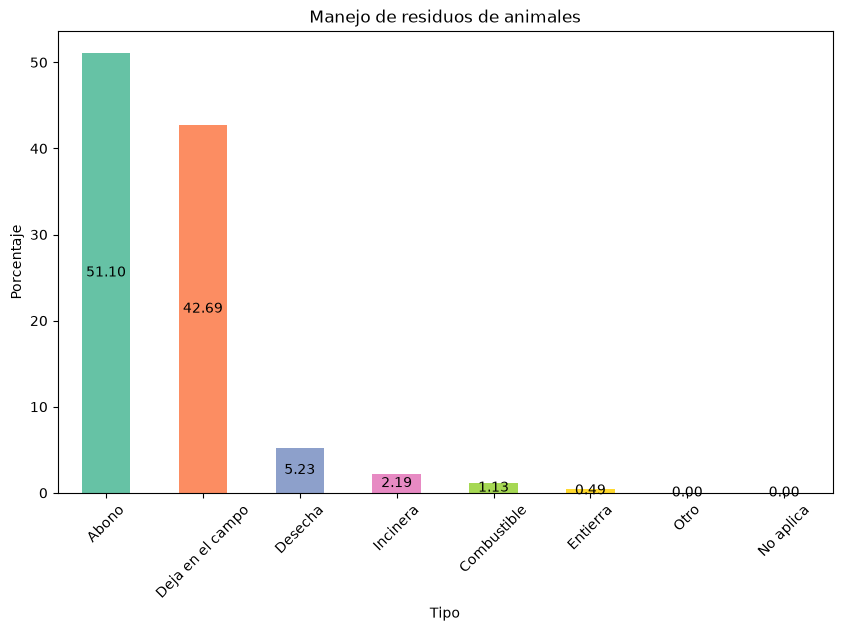

In [190]:
cmap = plt.get_cmap("Set2", len(frer_manejo_res_anim))
colores = [cmap(i) for i in range(len(frer_manejo_res_anim))]

plt.figure(figsize=(9,9))

gr_reg_manejo_res_anim = frer_manejo_res_anim.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_manejo_res_anim.set_title("Manejo de residuos de animales")
gr_reg_manejo_res_anim.set_xlabel("Tipo")
gr_reg_manejo_res_anim.set_ylabel("Porcentaje")  


for container in gr_reg_manejo_res_anim.containers:
    gr_reg_manejo_res_anim.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 45)
plt.show()

### Actividad en unidades en el último año

In [203]:
df_lalibertad["P142_1"].value_counts()

P142_1
1.0    1367
0.0      48
Name: count, dtype: int64

In [192]:
df_lalibertad["P142_2"].value_counts()

P142_2
1    988
0    427
Name: count, dtype: int64

In [193]:
df_lalibertad["P142_3"].value_counts()

P142_3
0.0    1377
1.0      38
Name: count, dtype: int64

In [194]:
tabla_actividad = df_lalibertad[["P142_1", "P142_2", "P142_3", "NSEGM", "UA"]]

In [195]:
actividad_merge = pd.merge(
    puntos_lalibertad,
    tabla_actividad,
    on = ["NSEGM", "UA"],
    how = "outer"
)

In [196]:
condiciones_actividad = [
    ((actividad_merge["P142_1"] == 1) & (actividad_merge["P142_2"] == 0)).fillna(False),
    ((actividad_merge["P142_1"] == 0) & (actividad_merge["P142_2"] == 1)).fillna(False),
    ((actividad_merge["P142_1"] == 1) & (actividad_merge["P142_2"] == 1)).fillna(False),
    ((actividad_merge["P142_1"] == 0) & (actividad_merge["P142_2"] == 0)).fillna(False)
]

categorias_actividad = ["AGRÍCOLA", "PECUARIA", "AMBAS", "INACTIVA"]

actividad_merge["ACTIVIDAD"] = np.select(
    condiciones_actividad,
    categorias_actividad,
    default = pd.NA
)

In [197]:
condiciones_actividad_color = [
    (actividad_merge["ACTIVIDAD"] == "AGRÍCOLA").fillna(False),
    (actividad_merge["ACTIVIDAD"] == "PECUARIA").fillna(False),
    (actividad_merge["ACTIVIDAD"] == "AMBAS").fillna(False),
    (actividad_merge["ACTIVIDAD"] == "INACTIVA").fillna(False)
]

colores_actividad = ["deepskyblue", "tomato", "lightgreen", "black"]

actividad_merge["color"] = np.select(
    condiciones_actividad_color,
    colores_actividad,
    default = "silver"
)

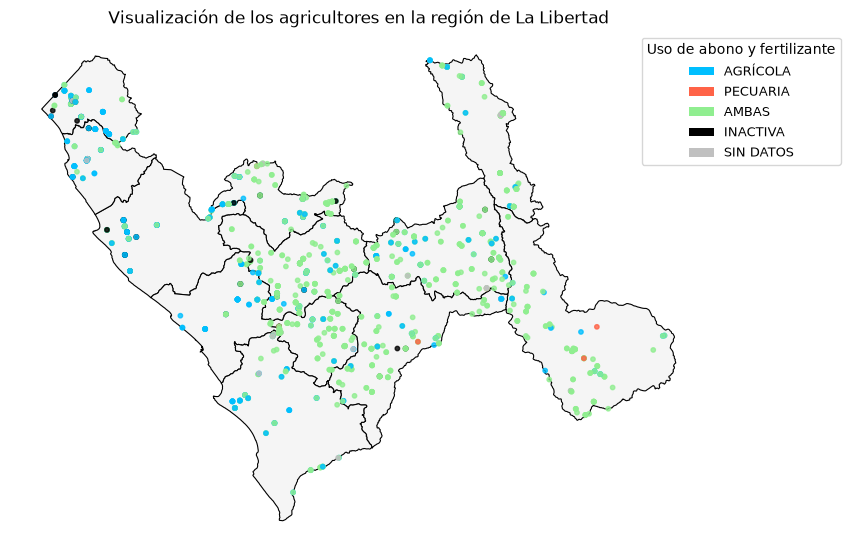

In [198]:
fig, ax = plt.subplots(figsize=(9, 9))

map_prov_lalibertad.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8
)

actividad_merge.plot(
    ax=ax,
    color=actividad_merge["color"],
    markersize=10,
    alpha=0.8
)

# Leyenda
leyenda = [
    Patch(facecolor="deepskyblue", label="AGRÍCOLA"),
    Patch(facecolor="tomato", label="PECUARIA"),
    Patch(facecolor="lightgreen", label="AMBAS"),
    Patch(facecolor="black", label="INACTIVA"),
    Patch(facecolor="silver", label="SIN DATOS")
]

ax.legend(
    handles=leyenda,
    title="Uso de abono y fertilizante",
    loc="upper right",
    fontsize=9,
    title_fontsize=10,
    bbox_to_anchor = (1.2,1)
)

ax.set_title("Visualización de los agricultores en la región de La Libertad")
ax.set_axis_off()

plt.show()

### Lugar de almacenamiento de la producción

In [199]:
almacen = {
    "P606_1": "Lugar refrigerado",
    "P606_2": "Intemperie",
    "P606_3": "Cuarto ventilado",
    "P606_4": "Cuarto inadecuado",
    "P606_6": "Venta inmediata",
    "P606_7": "No para consumo humano",
    "P606_5": "Otro"
}

columnas_almacen = list(almacen.keys())

In [200]:
frec_almacen = (
    df_lalibertad[columnas_almacen]
    .sum()
    .sort_values(ascending = False)
    .rename(index = almacen)
)

frer_almacen = (frec_almacen/len(df_lalibertad)*100).round(2)
frer_almacen

Cuarto ventilado          65.94
Venta inmediata           60.28
Cuarto inadecuado         23.75
Lugar refrigerado          6.08
Intemperie                 2.54
No para consumo humano     2.26
Otro                       0.21
dtype: float64

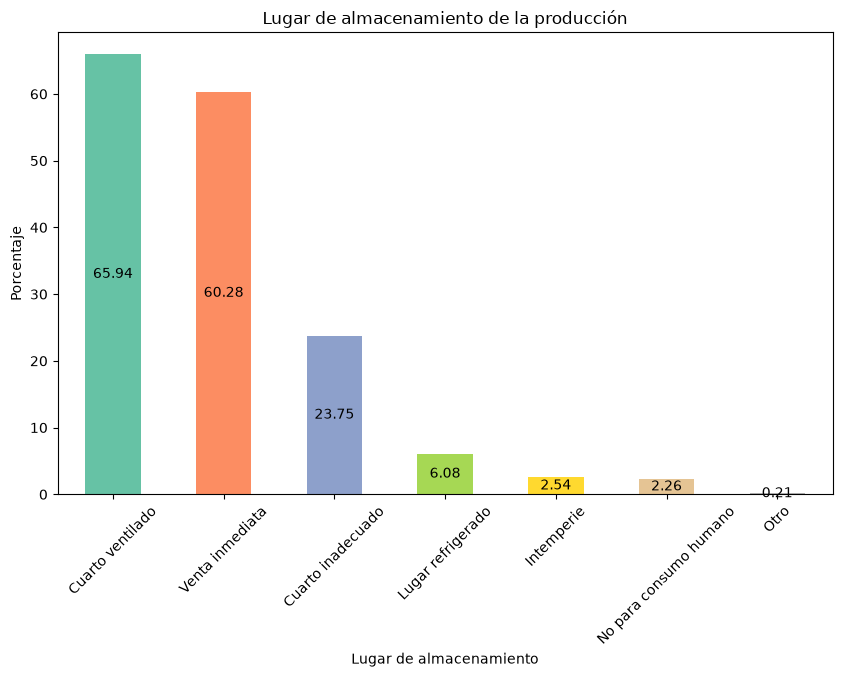

In [201]:
cmap = plt.get_cmap("Set2", len(frer_almacen))
colores = [cmap(i) for i in range(len(frer_almacen))]

gr_reg_almacen = frer_almacen.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_almacen.set_title("Lugar de almacenamiento de la producción")
gr_reg_almacen.set_xlabel("Lugar de almacenamiento")
gr_reg_almacen.set_ylabel("Porcentaje")  


for container in gr_reg_almacen.containers:
    gr_reg_almacen.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 45)
plt.show()